In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:

!pip -q install datasets

from datasets import load_dataset
import pandas as pd

print("Dataset library is ready!")


Dataset library is ready!


In [5]:

from datasets import load_dataset
import pandas as pd

dataset = load_dataset(
    "stanfordnlp/imdb",
    split="train"
)

df = pd.DataFrame(dataset)
df = df.sample(n=10000, random_state=42).reset_index(drop=True)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())
display(df.head())


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Dataset loaded successfully!
Dataset shape: (10000, 2)
Column names: ['text', 'label']


,text,label
0,"Dumb is as dumb does, in this thoroughly unint...",0
1,I dug out from my garage some old musicals and...,1
2,After watching this movie I was honestly disap...,0
3,This movie was nominated for best picture but ...,1
4,Just like Al Gore shook us up with his painful...,1


In [6]:

from datasets import load_dataset
import pandas as pd

dataset = load_dataset(
    "goosmanlei/amazon_reviews_multi",
    "en",
    split="train"
)

df = pd.DataFrame(dataset)
df = df.sample(n=10000, random_state=42).reset_index(drop=True)

df = df[["review_title", "review_body", "stars"]].copy()
df["text"] = (
    df["review_title"].fillna("") + " " +
    df["review_body"].fillna("")
).str.strip()

df["sentiment"] = df["stars"].map({
    1: "Negative",
    2: "Negative",
    3: "Neutral",
    4: "Positive",
    5: "Positive"
})

df = df.dropna(subset=["sentiment", "text"])
df = df[df["text"].str.len() > 0].reset_index(drop=True)

print("Product review dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nSentiment distribution:")
print(df["sentiment"].value_counts())
display(df[["text", "stars", "sentiment"]].head())


README.md:   0%|          | 0.00/2.62k [00:00<?, ?B/s]

en/train.jsonl.gz: reconstructing file:   0%|          |  0.00B / 21.5MB            

en/train.jsonl.gz: downloading bytes:           |  0.00B            

en/validation.jsonl.gz: reconstructing file:   0%|          |  0.00B /  542kB            

en/validation.jsonl.gz: downloading bytes:           |  0.00B            

...

Generating train split:   0%|          | 0/200000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Product review dataset loaded successfully!
Dataset shape: (10000, 5)

Sentiment distribution:
sentiment
Positive    4069
Negative    3949
Neutral     1982
Name: count, dtype: int64


,text,stars,sentiment
0,Not strong enough to run a small 120v vacuum c...,3,Neutral
1,"Crap The leg openings are a little small, but ...",2,Negative
2,Four Stars Really cute mug. I would have given...,4,Positive
3,Lies!! Well it’s looks and feels okay but it m...,2,Negative
4,"Thin and bendable :( Very, very thin, you can ...",1,Negative


In [7]:

from sklearn.model_selection import train_test_split

X = df["text"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dataset split completed!")
print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))
print("\nTraining sentiment distribution:")
print(y_train.value_counts())
print("\nTesting sentiment distribution:")
print(y_test.value_counts())


Dataset split completed!
Training reviews: 8000
Testing reviews: 2000

Training sentiment distribution:
sentiment
Positive    3255
Negative    3159
Neutral     1586
Name: count, dtype: int64

Testing sentiment distribution:
sentiment
Positive    814
Negative    790
Neutral     396
Name: count, dtype: int64


In [8]:

from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("TF-IDF conversion completed!")
print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)
print("Number of TF-IDF features:", X_train_tfidf.shape[1])


TF-IDF conversion completed!
Training matrix shape: (8000, 10000)
Testing matrix shape: (2000, 10000)
Number of TF-IDF features: 10000


In [9]:

models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(
        max_iter=1000
    ),
    "Linear SVM": LinearSVC(),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

print("Four classifiers are ready!")
for name in models:
    print("-", name)


Four classifiers are ready!
- Naive Bayes
- Logistic Regression
- Linear SVM
- Random Forest


In [10]:

results = []
trained_models = {}
predictions = {}

for name, model in models.items():
    print(f"Training {name}...")

    start_time = time.time()

    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)

    elapsed_time = time.time() - start_time

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    results.append({
        "Classifier": name,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1-score": f1,
        "Time (seconds)": elapsed_time
    })

    trained_models[name] = model
    predictions[name] = y_pred

    print(f"{name} completed. Accuracy: {accuracy:.4f}")

results_df = pd.DataFrame(results)
print("\nAll classifiers trained successfully!")
display(results_df.round(4))


Training Naive Bayes...
Naive Bayes completed. Accuracy: 0.7050
Training Logistic Regression...
Logistic Regression completed. Accuracy: 0.7100
Training Linear SVM...
Linear SVM completed. Accuracy: 0.6825
Training Random Forest...
Random Forest completed. Accuracy: 0.6905

All classifiers trained successfully!


,Classifier,Accuracy,Macro Precision,Macro Recall,Macro F1-score,Time (seconds)
0,Naive Bayes,0.7050,0.6050,0.5884,0.5312,0.0945
1,Logistic Regression,0.7100,0.6438,0.6161,0.5988,4.0172
2,Linear SVM,0.6825,0.6096,0.6067,0.6014,0.1896
3,Random Forest,0.6905,0.6313,0.5875,0.5545,26.4763


In [11]:

print("CLASSIFIER COMPARISON RESULTS")
print("=" * 60)

display(
    results_df.sort_values(
        by="Macro F1-score",
        ascending=False
    ).round(4)
)

best_model_name = results_df.loc[
    results_df["Macro F1-score"].idxmax(),
    "Classifier"
]

print("\nBest classifier by Macro F1-score:", best_model_name)


CLASSIFIER COMPARISON RESULTS


,Classifier,Accuracy,Macro Precision,Macro Recall,Macro F1-score,Time (seconds)
2,Linear SVM,0.6825,0.6096,0.6067,0.6014,0.1896
1,Logistic Regression,0.7100,0.6438,0.6161,0.5988,4.0172
3,Random Forest,0.6905,0.6313,0.5875,0.5545,26.4763
0,Naive Bayes,0.7050,0.6050,0.5884,0.5312,0.0945



Best classifier by Macro F1-score: Linear SVM


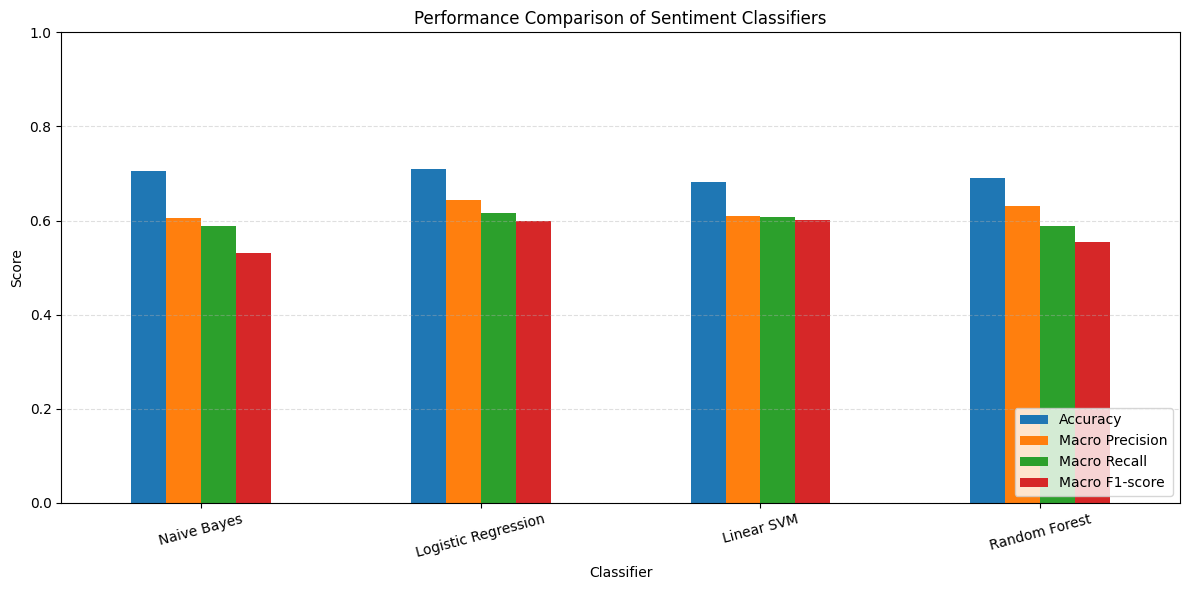

In [12]:

metrics_to_plot = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1-score"
]

results_df.set_index("Classifier")[metrics_to_plot].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Performance Comparison of Sentiment Classifiers")
plt.ylabel("Score")
plt.xlabel("Classifier")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


In [13]:

best_predictions = predictions[best_model_name]

print("BEST CLASSIFIER:", best_model_name)
print("=" * 60)

print(classification_report(
    y_test,
    best_predictions,
    labels=["Negative", "Neutral", "Positive"],
    target_names=["Negative", "Neutral", "Positive"],
    zero_division=0,
    digits=4
))


BEST CLASSIFIER: Linear SVM
              precision    recall  f1-score   support

    Negative     0.7209    0.7684    0.7439       790
     Neutral     0.3796    0.2348    0.2902       396
    Positive     0.7284    0.8170    0.7701       814

    accuracy                         0.6825      2000
   macro avg     0.6096    0.6067    0.6014      2000
weighted avg     0.6564    0.6825    0.6647      2000



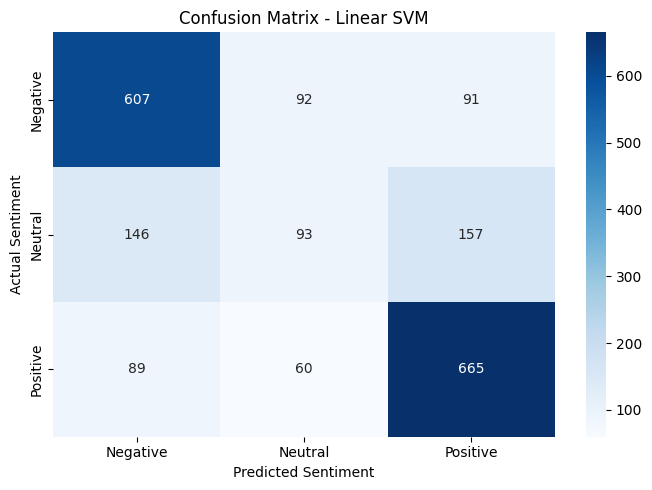

In [14]:

best_predictions = predictions[best_model_name]

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=["Negative", "Neutral", "Positive"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.tight_layout()
plt.show()


In [15]:

print("WHAT-IF EXPERIMENT")
print("=" * 45)

# Original Linear SVM result
original_f1 = results_df.loc[
    results_df["Classifier"] == "Linear SVM",
    "Macro F1-score"
].iloc[0]

# Create TF-IDF features using only 5,000 terms
vectorizer_5000 = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=5000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_train_5000 = vectorizer_5000.fit_transform(X_train)
X_test_5000 = vectorizer_5000.transform(X_test)

# Train and evaluate Linear SVM
svm_5000 = LinearSVC()
svm_5000.fit(X_train_5000, y_train)
pred_5000 = svm_5000.predict(X_test_5000)

new_f1 = f1_score(
    y_test, pred_5000,
    average="macro",
    zero_division=0
)

print("Original features: 10,000")
print(f"Original Linear SVM Macro F1: {original_f1:.4f}")
print("\nExperiment features:", X_train_5000.shape[1])
print(f"New Linear SVM Macro F1: {new_f1:.4f}")
print(f"F1-score difference: {new_f1 - original_f1:+.4f}")


WHAT-IF EXPERIMENT
Original features: 10,000
Original Linear SVM Macro F1: 0.6014

Experiment features: 5000
New Linear SVM Macro F1: 0.5918
F1-score difference: -0.0096


In [16]:

# Save the classifier comparison results
results_df.to_csv(
    "classifier_comparison_results.csv",
    index=False
)

print("Results table saved successfully!")
display(results_df.round(4))


Results table saved successfully!


,Classifier,Accuracy,Macro Precision,Macro Recall,Macro F1-score,Time (seconds)
0,Naive Bayes,0.7050,0.6050,0.5884,0.5312,0.0945
1,Logistic Regression,0.7100,0.6438,0.6161,0.5988,4.0172
2,Linear SVM,0.6825,0.6096,0.6067,0.6014,0.1896
3,Random Forest,0.6905,0.6313,0.5875,0.5545,26.4763
